# Critical-current oscillations in the CSC (Supplementary Fig. S54; Fig. R9 of the response letter)

File 1400 (same data as Fig. 2e). Output: `figs/csc_Ic_osc_widthfit_full.pdf`.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("../utils"))  # repo utils/ (vendored sweep + shared helpers)
from fft_sup_imports import *
%matplotlib inline
update_rc_params('paper')

In [2]:
from scipy.signal import savgol_filter, medfilt

def critical_current(idc, R, thresh=25.0, smooth=5, center=None, despike=5):
    """Threshold-crossing critical current from an R(B, Idc) map.

    idc    : (nI,) bias axis, in the units you plot (nA here)
    R      : (nB, nI) resistance map -- i.e. `zs`, BEFORE the .T for pcolormesh
    thresh : resistance defining the SC->normal boundary, in ohms
    center : bias to walk outward from; None -> minimum of the B-median profile
    Returns (Icp, Icm, center), NaN where no crossing was found.
    """
    R = np.ma.filled(np.ma.asarray(R).astype(float), np.nan)
    idc = np.asarray(idc, float)
    n = R.shape[0]

    def _sm(v):
        if smooth and 2 < smooth < len(v):
            return savgol_filter(v, smooth if smooth % 2 else smooth + 1, 2)
        return v

    if center is None:
        center = idc[int(np.nanargmin(_sm(np.nanmedian(R, axis=0))))]
    c = int(np.abs(idc - center).argmin())

    Icp, Icm = np.full(n, np.nan), np.full(n, np.nan)
    for j in range(n):
        r = _sm(R[j].copy())
        for k in range(c, len(r)):                       # walk to +bias
            if r[k] > thresh:
                f = (thresh - r[k-1]) / (r[k] - r[k-1]) if k > 0 and r[k] != r[k-1] else 0.0
                Icp[j] = idc[k-1] + f * (idc[k] - idc[k-1]) if k > 0 else idc[k]
                break
        for k in range(c, -1, -1):                       # walk to -bias
            if r[k] > thresh:
                f = (thresh - r[k+1]) / (r[k] - r[k+1]) if k < len(r)-1 and r[k] != r[k+1] else 0.0
                Icm[j] = idc[k+1] + f * (idc[k] - idc[k+1]) if k < len(r)-1 else idc[k]
                break

    if despike and despike > 1:
        w = despike if despike % 2 else despike + 1
        for A in (Icp, Icm):
            g = np.isfinite(A)
            if g.sum() > w:
                A[g] = medfilt(A[g], w)
    return Icp, Icm, center

In [3]:
# ---- Two-panel: (a) CSC critical-current oscillations (Fig. 2e, file 1400) + (b) window width down to B = 0, cosine fit extrapolated ----
# (a) dV/dI(B, I_dc) on sr830_2 with the critical_current(thresh=10) boundary; dotted guides at the fitted
#     minima of the width in (b), spaced by the fitted period.
# (b) Width of the zero-resistance window, W = I_hi - I_lo, where dV/dI crosses RTH (no centre needed),
#     plotted over the full B < 0 range; fit to a + s*B + A*cos(2*pi*B/P + phi) only over BLO..BHI (ends at
#     -16 mT to exclude the spike near -10 mT); fit solid inside the fit range, dashed where extrapolated.
#     With ~3 periods in the window this is more direct than an FFT (resolution ~1/(84 mT) ~ 12 /T).
#     Robustness (window start -100/-95/-90 mT, end -8/-12/-16 mT, RTH 5/10/20 ohm): P = 27.9-28.8 mT.
#     The formal fit error is too small (residuals are correlated) -- quote the robustness spread.
from matplotlib.gridspec import GridSpec
from scipy.optimize import curve_fit

file, ind = 1400, 2
BLO, BHI = -0.1, -0.016     # T
RTH = 10.0                  # ohm

data = sl.pload(file_path, file)
Idc = data['xs'] * 10                         # nA, swept -2.5 -> +2.5 at each field
Bs = data['ys']                               # T
R = data[f'sr830_{ind}_X'] / data['sr830_4_X']

_o = np.argsort(Bs); _B = Bs[_o]; _R = R[_o, :]
_m = (_B >= BLO) & (_B <= BHI)
Bw, Rw = _B[_m], _R[_m, :]
Bm = Bw * 1e3                                 # mT

def band_edges(Iax, r, rth):
    below = r < rth; jmin = np.argmin(r)
    if not below[jmin]:
        return np.nan, np.nan
    lo = jmin
    while lo - 1 >= 0 and below[lo - 1]: lo -= 1
    hi = jmin
    while hi + 1 < len(r) and below[hi + 1]: hi += 1
    Ilo = Iax[lo] if lo == 0 else Iax[lo-1] + (rth-r[lo-1])/(r[lo]-r[lo-1])*(Iax[lo]-Iax[lo-1])
    Ihi = Iax[hi] if hi == len(r)-1 else Iax[hi] + (rth-r[hi])/(r[hi+1]-r[hi])*(Iax[hi+1]-Iax[hi])
    return Ilo, Ihi
edges = np.array([band_edges(Idc, Rw[i], RTH) for i in range(len(Bw))])
W = edges[:, 1] - edges[:, 0]
assert not np.isnan(W).any()

# width over the full B < 0 range, for display only (NaN where there is no zero-resistance window)
_mall = _B < 0
B_all = _B[_mall] * 1e3
edges_all = np.array([band_edges(Idc, r, RTH) for r in _R[_mall, :]])
W_all = edges_all[:, 1] - edges_all[:, 0]
print(f"full range: {np.isnan(W_all).sum()} of {len(W_all)} fields have no window below {RTH:.0f} ohm")

def model(B, a, s, A, P, phi):
    return a + s*B + A*np.cos(2*np.pi*B/P + phi)

best = None
for phi0 in np.linspace(0, 2*np.pi, 8, endpoint=False):
    for P0 in (25, 30, 35):
        try:
            p, cov = curve_fit(model, Bm, W, p0=[W.mean(), 0, 0.2, P0, phi0], maxfev=20000)
        except RuntimeError:
            continue
        r = np.sum((W - model(Bm, *p))**2)
        if 5 < p[3] < 80 and (best is None or r < best[2]):
            best = (p, cov, r)
pW, cW, _ = best
if pW[2] < 0:                                 # make A > 0 so minima sit at phase = pi
    pW[2], pW[4] = -pW[2], pW[4] + np.pi
P_fit = pW[3]
print(f"width: P = {P_fit:.1f} mT (formal +/- {np.sqrt(cW[3, 3]):.1f}), A = {pW[2]:.3f} nA")

# minima of the cosine term, B = P*(pi - phi)/(2 pi) + k*P, inside the plotted range
B_min0 = P_fit * (np.pi - pW[4]) / (2*np.pi)
guides = [B_min0 + k*P_fit for k in range(-10, 10) if -95 < B_min0 + k*P_fit < 0]
print("guides (mT):", np.round(guides, 1))

full range: 0 of 200 fields have no window below 10 ohm
width: P = 27.9 mT (formal +/- 0.3), A = 0.276 nA
guides (mT): [-78.1 -50.2 -22.3]


full-fit minima (mT): [-79.  -51.2 -23.3]  shift from cosine minima (mT): [-0.96 -0.96 -0.96]


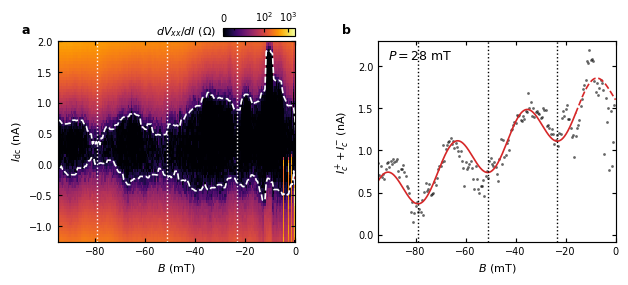

In [4]:
# ---- Fig. R (critical-current oscillations): guides at the minima of the FULL fit (linear + cosine), not the cosine term ----
# Reuses cell 47's state (pW, model, Bm, B_all, W_all, Bs, Idc, R, P_fit). The linear slope adds a constant to the
# derivative, so every minimum shifts by the same amount (~ -1 mT here); the period is unchanged.
from scipy.optimize import minimize_scalar

guides_full = [minimize_scalar(lambda b: model(b, *pW), bounds=(x - P_fit/4, x + P_fit/4), method='bounded').x
               for x in guides]
print("full-fit minima (mT):", np.round(guides_full, 1),
      " shift from cosine minima (mT):", np.round(np.array(guides_full) - np.array(guides), 2))

fig = plt.figure(figsize=(7.2, 2.6))
gs = GridSpec(1, 2, figure=fig, wspace=0.35)
axA = fig.add_subplot(gs[0, 0])
axB = fig.add_subplot(gs[0, 1])

# (a)
norm = colors.SymLogNorm(linthresh=25, vmin=0, vmax=0.2E4)
pm = axA.pcolormesh(1000*Bs, Idc, R.T, norm=norm, cmap='inferno', rasterized=True, lw=0)
Icp, Icm, I0 = critical_current(Idc, R, thresh=10.0, smooth=1, despike=5, center=0.25)
axA.plot(Bs*1000, Icp, '--', color='w', lw=1.2)
axA.plot(Bs*1000, Icm, '--', color='w', lw=1.2)
for x in guides_full:
    axA.axvline(x, color='w', ls='dotted', lw=1)
axA.set_xlim(-95, 0.0)
axA.set_ylim(-1.25, 2)
axA.set_xlabel(r'$B$ (mT)')
axA.set_ylabel(r'$I_{\mathrm{dc}}$ (nA)')

fig.canvas.draw()
pos = axA.get_position()
cb_width = 0.10
cax = fig.add_axes([pos.x1 - cb_width, pos.y1 + 0.02, cb_width, 0.08 / fig.get_size_inches()[1]])
cb = plt.colorbar(pm, cax=cax, ticks=[0, 100, 1000], orientation='horizontal')
cb.set_ticklabels(['0', r'$10^2$', r'$10^3$'])
cb.ax.annotate(r'$dV_{xx}/dI$ ($\Omega$)', xy=(-0.10, 0.5), xycoords='axes fraction',
               ha='right', va='center', fontsize=plt.rcParams['axes.labelsize'])
cb.ax.xaxis.set_ticks_position('top'); cb.ax.xaxis.set_label_position('top')

# (b)
Bfine = np.linspace(Bm.min(), Bm.max(), 500)
Bext = np.linspace(Bm.max(), 0, 200)
axB.plot(B_all, W_all, 'o', ms=2, color='k', alpha=0.6, mew=0)
axB.plot(Bfine, model(Bfine, *pW), '-', color='tab:red', lw=1.2)
axB.plot(Bext, model(Bext, *pW), '--', color='tab:red', lw=1.2)
for x in guides_full:
    axB.axvline(x, color='k', ls='dotted', lw=1)
axB.text(0.04, 0.96, rf'$P = {P_fit:.0f}$ mT', transform=axB.transAxes, ha='left', va='top')
axB.set_xlim(axA.get_xlim())
axB.set_xlabel(r'$B$ (mT)')
axB.set_ylabel(r'$I_c^{+} + I_c^{-}$ (nA)')

for ax, letter in [(axA, 'a'), (axB, 'b')]:
    p = ax.get_position()
    fig.text(p.x0 - 0.05, p.y1 + 0.03, letter, fontweight='bold')

save_fig(fig, "csc_Ic_osc_widthfit_full")
plt.show()